<a href="https://colab.research.google.com/github/Laura-RFLopes/python_sis_26_2/blob/laura_lopes/aula12/laura_lopes_aula_12_exercicio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install openpyxl


In [3]:
# Importando a biblioteca
import openpyxl
from openpyxl import Workbook

# Etapa 1: Instalação e Criação.

# Criando uma nova pasta de trabalho
workbook = Workbook()

# Criando uma aba chamada Servidores
planilha = workbook.active
planilha.title = "Servidores"

# Criando o cabeçalho
cabecalho = [
    "Hostname",
    "IP",
    "Memória (GB)",
    "Uso de Disco (%)",
    "Status"
]

planilha.append(cabecalho)

# Salvando a planilha
workbook.save("inventario_servidores.xlsx")

print("Planilha criada com sucesso!")


Planilha criada com sucesso!


In [4]:

# Etapa 2: Edição.

# Inserindo dados dos servidores
servidores = [
    ["SRV-01", "192.168.0.10", 16, 65, "Ativo"],
    ["SRV-02", "192.168.0.11", 32, 85, "Ativo"],
    ["SRV-03", "192.168.0.12", 8, 90, "Ativo"],
    ["SRV-04", "192.168.0.13", 16, 50, "Inativo"]
]

# Adicionando os servidores na planilha
for servidor in servidores:
    planilha.append(servidor)

# Verificando o uso do disco
for linha in range(2, planilha.max_row + 1):

    uso_disco = planilha.cell(row=linha, column=4).value

    if uso_disco >= 80:
        print(f"ALERTA: O servidor {planilha.cell(row=linha, column=1).value} precisa de expansão de armazenamento!")

# Salvando as alterações
workbook.save("inventario_servidores.xlsx")


ALERTA: O servidor SRV-02 precisa de expansão de armazenamento!
ALERTA: O servidor SRV-03 precisa de expansão de armazenamento!


In [5]:
# Etapa 3: Abertura e Extração do Log

# Criando o arquivo de log
with open("log.txt", "w", encoding="utf-8") as log:

    log.write("""2026-10-14 08:30:15 - INFO - Sistema inicializado com sucesso
2026-10-14 08:31:02 - INFO - Usuario 'admin' realizou login
2026-10-14 08:35:22 - AVISO - Tentativa de acesso com senha incorreta: usuario 'bat'
2026-10-14 08:35:40 - SUCESSO - Usuario 'bat' realizou login
2026-10-14 08:40:11 - ERRO - Falha ao conectar ao banco de dados: timeout
2026-10-14 08:42:00 - INFO - Conexao reestabelecida
""")

print("Arquivo de log criado!")

# Lista para armazenar os dados extraídos
dados_logs = []

try:

    with open("log.txt", "r", encoding="utf-8") as log:

        for linha in log:

            partes = linha.strip().split(" - ", 2)

            if len(partes) == 3:

                data_hora = partes[0]
                tipo_evento = partes[1]
                mensagem = partes[2]

                dados_logs.append([
                    data_hora,
                    tipo_evento,
                    mensagem
                ])

                print("Evento:", tipo_evento)

except FileNotFoundError:

    print("Erro: arquivo log.txt não encontrado!")


Arquivo de log criado!
Evento: INFO
Evento: INFO
Evento: AVISO
Evento: SUCESSO
Evento: ERRO
Evento: INFO


In [6]:
# Etapa 4: Salvando

# Criando uma nova planilha
workbook_logs = Workbook()

# Selecionando a aba
planilha_logs = workbook_logs.active
planilha_logs.title = "Auditoria Logs"

# Criando o cabeçalho
cabecalho_logs = ["Data/Hora", "Tipo de Evento", "Mensagem"]

planilha_logs.append(cabecalho_logs)

# Inserindo os dados extraídos
for registro in dados_logs:
    planilha_logs.append(registro)

# Salvando o arquivo Excel
workbook_logs.save("auditoria_logs.xlsx")

print("Arquivo auditoria_logs.xlsx criado com sucesso!")

Arquivo auditoria_logs.xlsx criado com sucesso!


In [7]:

# Instalando a biblioteca
!pip install psutil

# Importando as bibliotecas
import psutil
import time

# Etapa 1: Captura de CPU e memória RAM.

# Capturando o uso da CPU
uso_cpu = psutil.cpu_percent(interval=None)

# Capturando o uso da memória RAM
uso_ram = psutil.virtual_memory().percent

print("Uso da CPU:", uso_cpu, "%")
print("Uso da RAM:", uso_ram, "%")


Uso da CPU: 31.3 %
Uso da RAM: 9.1 %


In [8]:

# Etapa 2: Ciclo de amostragem.

# Realizando 5 iterações
for i in range(1, 6):

    uso_cpu = psutil.cpu_percent(interval=None)
    uso_ram = psutil.virtual_memory().percent

    print(f"Iteração {i}")
    print(f"Uso da CPU: {uso_cpu}%")
    print(f"Uso da RAM: {uso_ram}%")

    time.sleep(1)


Iteração 1
Uso da CPU: 46.1%
Uso da RAM: 8.6%
Iteração 2
Uso da CPU: 89.4%
Uso da RAM: 9.0%
Iteração 3
Uso da CPU: 42.9%
Uso da RAM: 9.2%
Iteração 4
Uso da CPU: 3.0%
Uso da RAM: 9.2%
Iteração 5
Uso da CPU: 3.0%
Uso da RAM: 9.2%


In [9]:

# Etapa 3: Criação do arquivo CSV.

# Definindo o caminho do arquivo
arquivo = "telemetria_sistema.csv"

# Criando o arquivo e gravando o cabeçalho
with open(arquivo, "w", encoding="utf-8") as csv:

    csv.write("Iteracao,Uso_CPU_Pct,Uso_RAM_Pct\n")

print("Arquivo telemetria_sistema.csv criado!")


Arquivo telemetria_sistema.csv criado!


In [10]:

# Etapa 4: Gravação das amostras.

# Realizando a coleta de dados
for i in range(1, 6):

    uso_cpu = psutil.cpu_percent(interval=None)
    uso_ram = psutil.virtual_memory().percent

    # Abrindo o arquivo no modo de anexação
    with open(arquivo, "a", encoding="utf-8") as csv:

        csv.write(f"{i},{uso_cpu},{uso_ram}\n")

    print(f"Iteração {i} registrada!")
    print(f"CPU: {uso_cpu}% | RAM: {uso_ram}%")

    time.sleep(1)

print("Coleta finalizada!")


Iteração 1 registrada!
CPU: 28.9% | RAM: 9.8%
Iteração 2 registrada!
CPU: 3.5% | RAM: 9.8%
Iteração 3 registrada!
CPU: 3.0% | RAM: 9.8%
Iteração 4 registrada!
CPU: 3.0% | RAM: 9.8%
Iteração 5 registrada!
CPU: 1.5% | RAM: 9.8%
Coleta finalizada!


In [11]:

# Instalando as bibliotecas
!pip install pandas matplotlib

# Importando as bibliotecas
import pandas as pd
import matplotlib.pyplot as plt

# Etapa 1: Ingestão do arquivo CSV.

# Lendo o arquivo
dados = pd.read_csv("telemetria_sistema.csv")

# Exibindo os dados
print(dados)


   Iteracao  Uso_CPU_Pct  Uso_RAM_Pct
0         1         28.9          9.8
1         2          3.5          9.8
2         3          3.0          9.8
3         4          3.0          9.8
4         5          1.5          9.8


In [12]:

# Etapa 2: Cálculo das médias.

# Calculando as médias
media_cpu = dados["Uso_CPU_Pct"].mean()
media_ram = dados["Uso_RAM_Pct"].mean()

# Exibindo o resumo descritivo
print("RESUMO DA TELEMETRIA DO SISTEMA")
print("--------------------------------")
print(f"Média de uso da CPU: {media_cpu:.2f}%")
print(f"Média de uso da RAM: {media_ram:.2f}%")


RESUMO DA TELEMETRIA DO SISTEMA
--------------------------------
Média de uso da CPU: 7.98%
Média de uso da RAM: 9.80%


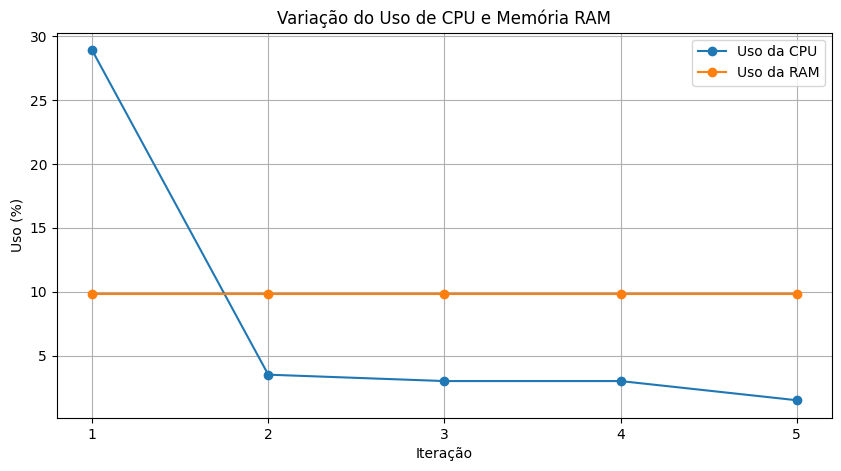

In [13]:

# Etapa 3: Gráfico de linha.

# Criando o gráfico
plt.figure(figsize=(10, 5))

# Linha de uso da CPU
plt.plot(dados["Iteracao"], dados["Uso_CPU_Pct"], marker="o", label="Uso da CPU")

# Linha de uso da RAM
plt.plot(dados["Iteracao"], dados["Uso_RAM_Pct"], marker="o", label="Uso da RAM")

# Configurando o gráfico
plt.title("Variação do Uso de CPU e Memória RAM")
plt.xlabel("Iteração")
plt.ylabel("Uso (%)")
plt.xticks(dados["Iteracao"])
plt.legend()
plt.grid(True)

# Exibindo o gráfico
plt.show()
